# ベルマン最適方程式と最適方策

『ゼロから作る Deep Learning ❹ 強化学習編』第 3 章「ベルマン方程式」3.4〜3.6 節 (pp. 77–85)

左と右に 1 マスずつある世界を考える。左のマスから右のマスに進むたびにリンゴが手に入り、その報酬は $+1$ である。右のマスから左に戻ると報酬は $0$ である。右のマスでさらに右を選ぶと、壁に当たってその場に残り、報酬は $-1$ となる。  
この世界では、2 つのマスを往復するのが最適である。左に戻るときの報酬は $0$ なのに、戻る行動の価値が $0$ より大きくなる理由について、ベルマン最適方程式を通して考える。  

### 目次

| 教科書の内容 | 目標 |
|---|---|
| 準備・復習 | 収益と価値を区別する |
| 3.4.1 状態価値関数 | 平均が最大値になる条件を知る |
| 3.4.2 行動価値関数 (Q 関数) | 次の状態ごとに行動を比べる |
| 3.5.1 ベルマン最適方程式の適用 | 2 マスの状態価値を求める |
| 3.5.2 最適方策を得る | 価値から行動を選ぶ |
| 3.6 まとめ | どこで平均と最大値を使うか確かめる |

### 復習：報酬、収益、価値

時刻 $t$ に状態 $s$ で行動 $a$ を選ぶと、次の状態 $s'$ に移り、報酬 $R_t$ を受け取る。このとき、収益 $G_t$ は時刻 $t$ から先の報酬を割り引いて足した値である。第 2 項以降から割引率 $\gamma$ をくくると、収益 $G_t$ は次の時刻からの収益 $G_{t+1}$ を用いて次のように表せる。

$$
\begin{aligned}
G_t &= R_t+\gamma R_{t+1}+\gamma^2R_{t+2}+\cdots\\
    &= R_t+\gamma(R_{t+1}+\gamma R_{t+2}+\cdots)\\
    &= R_t+\gamma G_{t+1}.
\end{aligned}
$$

時刻 $t$ からの収益 $G_t=R_t+\gamma G_{t+1}$ は、今の報酬 $R_t$ に、その後の収益を割り引いた $\gamma G_{t+1}$ を加えた値である。同じ状態から出発しても、選ぶ行動や移動先によって $G_t$ の値は変わり得る。状態価値と行動価値はどちらも、この $G_t$ の期待値 (取り得る値にそれぞれの確率を掛けて足した値) である。

状態価値 $v_\pi(s)$ とは、時刻 $t$ に状態 $s$ から出発し、最初の行動から方策 $\pi$ に従ったときの $G_t$ の期待値である。

$$
v_\pi(s)=\mathbb{E}_\pi\!\left[G_t \mid S_t=s\right].
$$

$\mathbb{E}_\pi$ は方策 $\pi$ のもとでの期待値を表す。縦線 $\mid$ の右側にある条件は $S_t=s$ (時刻 $t$ の状態が $s$) だけなので、最初の行動ごとの期待収益を、その行動を選ぶ確率 $\pi(a\mid s)$ で平均する。

行動価値 $q_\pi(s,a)$ とは、同じ状態 $s$ で最初の行動を $a$ に指定し、次の行動から方策 $\pi$ に従ったときの $G_t$ の期待値である。

$$
q_\pi(s,a)=\mathbb{E}_\pi\!\left[G_t \mid S_t=s,\,A_t=a\right].
$$

ここでは $A_t=a$ (時刻 $t$ の行動が $a$) という条件が加わる。たとえば右のマスから左に戻る場合、その行動の報酬は $R_t=0$ だが、平均した収益は $G_t=0+\gamma G_{t+1}$ である。左に戻った後の収益も行動価値に含まれる。

| 記号 | 意味 |
|---|---|
| $\pi(a\mid s)$ | 状態 $s$ で行動 $a$ を選ぶ確率。行動の選び方を定める規則が方策 $\pi$ である |
| $p(s'\mid s,a)$ | 状態 $s$ で行動 $a$ を選んだとき、次の状態が $s'$ になる確率 |
| $r(s,a,s')$ | $s$ から行動 $a$ で $s'$ に移ったときの報酬。この遷移で報酬が一定でない場合はその期待値 |

## 3.4 ベルマン最適方程式

### 3.4.1 状態価値関数におけるベルマン最適方程式

ベルマン方程式は、ある方策 $\pi$ に従うとき、今の状態の価値を「今の報酬」と「次の状態の価値」から表す式であり、直前に見た収益の式にもとづく。

$$
G_t = R_t + \gamma G_{t+1}.
$$

この式では、収益 $G_t$ を、今の行動で得る報酬 $R_t$ と、次の時刻からの収益を割り引いた $\gamma G_{t+1}$ に分けている。状態 $s$ から方策 $\pi$ に従うという条件で両辺の期待値を取ると、左辺は状態価値 $v_\pi(s)$ になる。右辺では、次にどの状態に移るかによって、その先に期待できる収益が変わる。そこで、移動先ごとに「今の報酬」と「移動先の価値の $\gamma$ 倍」を足し、行動と移動先がそれぞれどの確率で決まるかを考えて平均する。

最適方策 $\pi_*$ とは、どの状態から始めても、収益の期待値を最大にする方策である。たとえば 2 マスの世界で、右のマスから左に戻るときの報酬は $0$ だが、左に戻れば次にまたリンゴを取れる。この先の報酬まで含めて行動を比べるのがポイントである。

ベルマン方程式はどの方策についても成り立つので、最適方策 $\pi_*$ にも適用できる。まずは一般の方策 $\pi$ について、最初の行動を $a$ に指定した場合と、最初の行動も方策に任せた場合のそれぞれを考える。

次の状態 $s'$ は行動 $a$ の選択だけでなく、環境にも依存する。収益の式の $R_t$ に対応するのが $r(s,a,s')$ であり、残りの $G_{t+1}$ の期待値に対応するのが $v_\pi(s')$ である。到達した状態 $s'$ ごとに、報酬に $\gamma v_\pi(s')$ を加える。その結果を遷移確率で平均したものが、行動 $a$ の価値であり、これが式 (3.13) に対応する。

$$
q_\pi(s,a)=\sum_{s'}p(s'\mid s,a)
 \bigl[r(s,a,s')+\gamma v_\pi(s')\bigr].
$$

行動も方策に任せるときは、さらに行動の選択確率で平均する。次の等式では、1 行目の $q_\pi(s,a)$ に上の式を代入することで 2 行目の式 (3.7) が得られる。

$$
\begin{aligned}
v_\pi(s)&=\sum_a\pi(a\mid s)q_\pi(s,a)\\
&=\sum_a\pi(a\mid s)
  \sum_{s'}p(s'\mid s,a)\bigl[r(s,a,s')+\gamma v_\pi(s')\bigr].
\end{aligned}
$$

これがベルマン方程式であり、どの方策 $\pi$ についても成り立つ。

この問題では状態と行動の数は有限で、報酬は有界 (1 回の報酬が常に決まった有限の範囲に収まる) であり、割引率は $0\leq\gamma<1$ である。このとき、どの状態から出発しても収益の期待値を最大にする最適方策 $\pi_*$ が存在する。状態 $s$ を固定し、方策を比べたときの最大の状態価値を $v_*(s)=\max_\pi v_\pi(s)=v_{\pi_*}(s)$ と書く。式 (3.7) に $\pi_*$ を代入する。

$$
v_*(s)=\sum_a\pi_*(a\mid s)
\sum_{s'}p(s'\mid s,a)\bigl[r(s,a,s')+\gamma v_*(s')\bigr].
\tag{3.15}
$$

教科書の図 3-12 と同じく、状態 $s$ で選べる行動を $a_1,a_2,a_3$ とする。式 (3.15) の内側の和を計算した結果が順に $-2,0,4$ だったとする。たとえば $4$ は、最初に $a_3$ を選び、その後は最適に行動したときの収益の期待値である。

どの値も $4$ 以下なので、行動をどんな確率で選んでも平均は $4$ を超えない。$a_3$ を確率 $1$ で選べば、平均はちょうど $4$ になる。最適方策 (常に最適な行動を選ぶ場合) では行動価値の平均がその最大値に一致するので、式 (3.15) の外側の和を $\max_a$ に置き換えられる。これが状態価値関数におけるベルマン最適方程式である。

$$
v_*(s)=\max_a\sum_{s'}p(s'\mid s,a)
\bigl[r(s,a,s')+\gamma v_*(s')\bigr].
\tag{3.16}
$$

$\max_a$ は行動 $a$ ごとに求めた候補のうち、最も大きい値を返す。最大値を取る行動が複数あれば、そのうちどれを選んでも状態価値は同じである。移動先 $s'$ は自分で選べないので、$s'$ については引き続き遷移確率で平均する。

### 3.4.2 Q 関数におけるベルマン最適方程式

行動価値関数 (Q 関数) $q_\pi(s,a)$ では、今の行動 $a$ は決まっている。次の状態 $s'$ に着いたら、今度は方策 $\pi$ に従って次の行動 $a'$ を選ぶ。そのため $v_\pi(s')=\sum_{a'}\pi(a'\mid s')q_\pi(s',a')$ であり、Q 関数のベルマン方程式は次の形になる。

$$
q_\pi(s,a)=\sum_{s'}p(s'\mid s,a)
\left[r(s,a,s')+\gamma\sum_{a'}\pi(a'\mid s')q_\pi(s',a')\right].
$$

最初に $a$ を選び、その後は最適に行動するときの行動価値を $q_*(s,a)$ と書く。上の式に最適方策 $\pi_*$ を代入する。

$$
q_*(s,a)=\sum_{s'}p(s'\mid s,a)
\left[r(s,a,s')+\gamma\sum_{a'}\pi_*(a'\mid s')q_*(s',a')\right].
\tag{3.17}
$$

次の状態 $s'$ に着いた時点では、そこで取れる行動のうち、行動価値が最大のものを選べる。したがって、式 (3.17) の角括弧の中では次の等式が成り立つ。

$$
\sum_{a'}\pi_*(a'\mid s')q_*(s',a')=\max_{a'}q_*(s',a').
$$

式 (3.17) の右辺を置き換えると、Q 関数におけるベルマン最適方程式が得られる。

$$
q_*(s,a)=\sum_{s'}p(s'\mid s,a)
\left[r(s,a,s')+\gamma\max_{a'}q_*(s',a')\right].
\tag{3.18}
$$

式 (3.16) で比べるのは、今の状態 $s$ で選ぶ行動 $a$ である。式 (3.18) で比べるのは、次の状態 $s'$ で選ぶ行動 $a'$ である。移動先ごとに次の行動を選べるため、$\max_{a'}$ は $s'$ に関する和の内側にある。最適方策は複数あり得るが、どの最適方策でも $v_*$、$q_*$ の値は同じである。

## 3.5 ベルマン最適方程式の例

### 3.5.1 ベルマン最適方程式の適用

2 マスのグリッドワールドでは、$L1$ から右に進んで $L2$ に入るたびに、リンゴを取って報酬 $+1$ を得る。$L2$ から左に戻ると報酬は $0$ である。壁に向かって進むと元のマスに残り、報酬 $-1$ を得る。リンゴを取ってもタスクは終わらない。

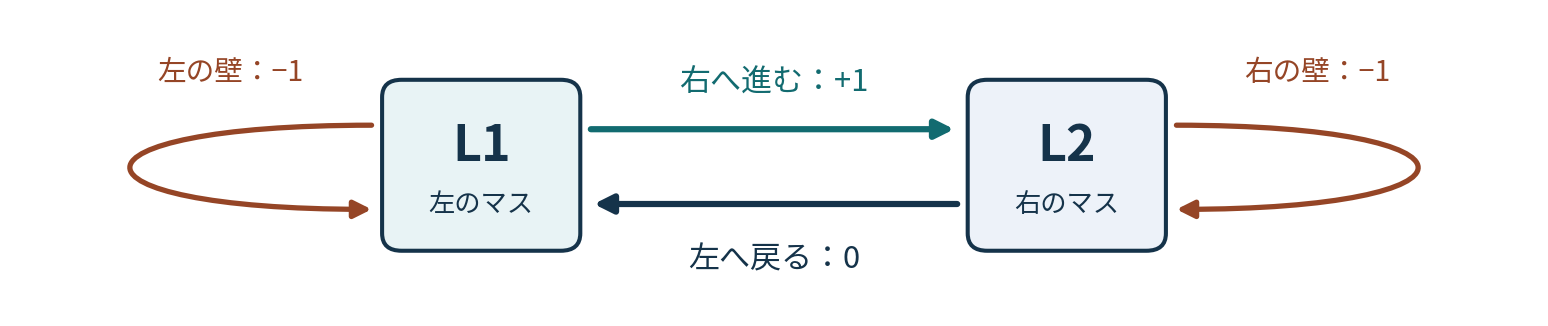

図 1：教科書の図 3-13 と同じ環境。矢印は 1 回の行動による移動を、矢印に沿った数値はそのときの報酬を示す。

この環境では、状態 $s$ と行動 $a$ を決めると移動先も 1 つに決まる。その移動先を $f(s,a)$ と書く。たとえば $L1$ で右を選ぶと必ず $L2$ に着くため、$L2$ に移る確率は $1$、$L1$ に残る確率は $0$ である。

したがって式 (3.16) の和では $s'=f(s,a)$ の項だけが残る。移動先を $s'$ と書けば、式は次のように簡単になる。

$$
v_*(s)=\max_a\bigl[r(s,a,s')+\gamma v_*(s')\bigr],
\qquad s'=f(s,a).
\tag{3.19}
$$

割引率を $\gamma=0.9$ とし、未知の状態価値を $x=v_*(L1)$、$y=v_*(L2)$ と置く。図 1 の矢印を 1 本ずつたどり、各行動の「今の報酬 $+$ 割り引いた移動先の価値」を書き出すと、次の表になる。

| 今の状態 | 行動 | 次の状態 | 今の報酬 | 比べる値 |
|---|---|---|---:|---|
| $L1$ | 左 | $L1$ | $-1$ | $-1+0.9x$ |
| $L1$ | 右 | $L2$ | $+1$ | $1+0.9y$ |
| $L2$ | 左 | $L1$ | $0$ | $0+0.9x$ |
| $L2$ | 右 | $L2$ | $-1$ | $-1+0.9y$ |

$x$ は左のマス $L1$ の最適状態価値、$y$ は右のマス $L2$ の最適状態価値です。

### 2 マスの状態価値を求める

状態ごとに表の右端を比べ、大きい方を選ぶと、次の 2 つの式が得られる。どちらの式も括弧の中は左、右の順である。

$$
\begin{aligned}
x&=\max\{-1+0.9x,\ 1+0.9y\},\\
y&=\max\{0+0.9x,\ -1+0.9y\}.
\end{aligned}
$$

$\max$ があるので、どの項を残すかはまだ決まっていない。そこで、リンゴを繰り返し取れる経路に着目し、$L1$ では右、$L2$ では左の値が大きいと仮定する。このとき $x=1+0.9y$、$y=0.9x$ となる。後者を前者に代入する。

$$
x=1+0.9(0.9x)=1+0.81x.
$$

$x$ と $y$ について解くと、

$$
x=\frac{1}{0.19}=\frac{100}{19},\qquad
y=0.9\times\frac{100}{19}=\frac{90}{19}.
$$

Python でも同じ 2 式を計算する。`v` には `[L1 の候補値, L2 の候補値]` が入る。この時点では往復すると仮定しただけなので、次に、選ばなかった行動も含めて左右の値を比べる。

In [1]:
import numpy as np

gamma = 0.9  # 1 ステップ後の価値に掛ける割引率
x = 1.0 / (1.0 - gamma**2)  # x = 1 + gamma**2 * x を解いた値
y = gamma * x                # L2 から左に戻ると、報酬は 0、移動先は L1
v = np.array([x, y])         # 0 番目が L1、1 番目が L2

print(f"L1 の候補値：{v[0]:.6f}")
print(f"L2 の候補値：{v[1]:.6f}")

L1 の候補値：5.263158
L2 の候補値：4.736842


### 3.5.2 最適方策を得る

最適な行動価値 $q_*(s,a)$ が分かっていれば、状態 $s$ でその値が最大になる行動を選べばよい。状態ごとに 1 つの行動を返す最適方策を $\mu_*$ と書く。

$$
\mu_*(s)=\underset{a}{\operatorname{argmax}}\ q_*(s,a).
\tag{3.20}
$$

$\max$ が返すのは最大の「値」、$\operatorname{argmax}$ が返すのはその値を取る「行動」である。たとえば図 3-12 の候補 $-2,0,4$ なら、最大値は $4$、その値を取る行動は $a_3$ である。同点なら最大値を取る行動から 1 つを選ぶ。

状態価値 $v_*$ から方策を求めるときは、移動先の確率と報酬も使う。教科書の式 (3.13) に最適方策を当てはめると、

$$
q_*(s,a)=\sum_{s'}p(s'\mid s,a)[r(s,a,s')+\gamma v_*(s')]
$$

である。この右辺を式 (3.20) の $q_*(s,a)$ に代入する。

$$
\mu_*(s)=\underset{a}{\operatorname{argmax}}\,
\sum_{s'}p(s'\mid s,a)\bigl[r(s,a,s')+\gamma v_*(s')\bigr].
\tag{3.21}
$$

### 左と右のどちらを選ぶか

先ほどの候補 $x=100/19$ と $y=90/19$ を使い、式 (3.21) で比べる値を計算する。たとえば $L1$ で左を選ぶと、壁に当たって $L1$ に残る。そこで今の報酬 $-1$ に $0.9x$ を加える。右を選べば、報酬 $+1$ に移動先 $L2$ の価値を割り引いた $0.9y$ を加える。

| 今の状態 | 左を選んだ場合 | 右を選んだ場合 | 最大値を取る行動 |
|---|---|---|---|
| $L1$ | $-1+0.9x=71/19$ | $1+0.9y=100/19$ | 右 |
| $L2$ | $0+0.9x=90/19$ | $-1+0.9y=62/19$ | 左 |

$L1$ では右の値が大きく、その値は $x$ に等しい。$L2$ では左の値が大きく、その値は $y$ に等しい。求めた $x,y$ は元のベルマン最適方程式を満たし、どちらの状態でも仮定した行動が最大値を取る。したがって、往復が最適方策である。

教科書の p. 82 では $L1$ と $L2$ の状態価値を $5.26,\ 4.73$ と表示し、p. 84 ではこの値を使って左右を比較している。この資料では分数のまま計算する。たとえば $L2$ の $90/19=4.736842\ldots$ は、小数第 3 位を四捨五入すると $4.74$ になる。

次のコードで同じ表を作る。`next_id` と `reward` はどちらも 2 行 2 列で、行は $L1$、$L2$ の順、列は左、右の順である。`next_id` には移動先の番号が、`reward` にはそのときの報酬が入る。たとえば `next_id[1, 0]` は「$L2$ で左を選んだときの移動先」を表し、値は $L1$ を指す `0` である。`v[next_id]` と書くと、各番号をその状態の価値に置き換えた 2 行 2 列の配列が得られる。

In [2]:
# 行は現在の状態、列は行動。移動先は L1 を 0、L2 を 1 として記録する。
next_id = np.array([[0, 1], [0, 1]])
reward = np.array([[-1.0, 1.0], [0.0, -1.0]])

next_v = v[next_id]          # 各行動で到着するマスの状態価値
q = reward + gamma * next_v  # 同じ位置の要素どうしで、今の報酬に gamma * next_v を加える

print("移動先の番号：", next_id, sep="\n")
print("移動先の価値：", next_v.round(4), sep="\n")
print("行動価値 (列は左、右の順)：", q.round(4), sep="\n")

移動先の番号：
[[0 1]
 [0 1]]
移動先の価値：
[[5.2632 4.7368]
 [5.2632 4.7368]]
行動価値 (列は左、右の順)：
[[3.7368 5.2632]
 [4.7368 3.2632]]


`q` の各行に、ある状態で左と右を選んだときの価値が並んだ。`axis=1` を指定すると、同じ行の 2 つの列を比較する。`max` で最大値を、`argmax` でその列番号を取り出す。

In [3]:
states = ("L1", "L2")
actions = ("左", "右")  # 列番号 0 が左、1 が右
best_value = q.max(axis=1)
best_action = q.argmax(axis=1)

for s, a in enumerate(best_action):
    print(f"{states[s]}：最大値 {best_value[s]:.4f}、列番号 {a} → {actions[a]}")

# 各行の最大値が手計算で得た状態価値と一致するかを確かめる。
np.testing.assert_allclose(best_value, v)

L1：最大値 5.2632、列番号 1 → 右
L2：最大値 4.7368、列番号 0 → 左


$L2$ で左を選ぶと、その場で得る報酬は $0$ でも、次の一手でまたリンゴを取れる。式 (3.21) のように、今選べる行動のうち行動価値が最大のものを選ぶ方策を貪欲方策 (greedy 方策) という。ここで比べた行動価値には移動先で得られる将来の報酬も含まれる。

## 3.6 まとめ

ベルマン方程式では、今の報酬に割り引いた次の状態価値を加えてその期待値を求める。教科書で取り上げられている 4 つの方程式を、どの行動の価値を比べるかに着目して整理する。

| 求める価値 | 方策 $\pi$ が決まっているとき (ベルマン方程式) | 最適に行動するとき (ベルマン最適方程式) |
|---|---|---|
| 状態価値 | $v_\pi(s)$：今の行動の価値を $\pi(a\mid s)$ で平均する | $v_*(s)$：今の行動 $a$ の価値のうち最大のものを選ぶ |
| 行動価値 | $q_\pi(s,a)$：移動先 $s'$ ごとに、次の行動の価値を $\pi(a'\mid s')$ で平均する | $q_*(s,a)$：移動先 $s'$ ごとに、次の行動 $a'$ の価値のうち最大のものを選ぶ |

いずれの式でも、移動先が複数あり得る場合は遷移確率 $p(s'\mid s,a)$ で平均する。2 マスの例では移動先が 1 つに決まるため、その和を省いて手で解けた。状態や行動の数が多い問題では、連立方程式を直接解く計算量が大きくなる。

最適行動価値 $q_*$ が分かれば、各状態で行動価値が最大になる行動を選ぶと最適方策が得られる。この例では $\mu_*(L1)=\text{右}$、$\mu_*(L2)=\text{左}$ となる。